In [2]:
from app_control.pure_functions import W_pred, corr_func, L_pred, smoother, solub, final_value, SED, file_finder
from matplotlib.ticker import MaxNLocator
import matplotlib as mpl
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import minimize


In [214]:


class DataManager:
    def __init__(self, omni_filename="expttsd", imed_filename="imed"):
        self.omni_filename = "expttsd"
        self.imed_filename = "imed"
        self.omni_folder = None
        self.DESC_best_W = [2]
        self.DESC_best = [1, 2]
        self.finaltime = 10  # minutes
        self.colors = ['orange', 'magenta', 'blue', 'red', 'green']
        self.conc_corr = True
        self.sizedata = []
        self.EVAL = []
        self.popt = [1, 0]
        self.read_files = []
        self.read_data_from = []
        self.COLUMNS = []
        self.PRE_COLUMNS = []
        self.PRO_COLUMNS = []
        
    def plot_generator(self):
        if not self.EVAL:
            return

        # Modern Matplotlib dark theme configuration
        mpl.rcParams.update({
            'font.size': 9, 'axes.labelsize': 9, 'axes.titlesize': 9,
            'xtick.labelsize': 9, 'ytick.labelsize': 9, 'legend.fontsize': 9,
            'grid.alpha': 0.3, 'grid.linewidth': 0.6, 'grid.linestyle': '--',
            'xtick.minor.visible': True, 'ytick.minor.visible': True,
            'figure.autolayout': True,
        })
        
        NBINS = 4
        self.fig, self.axT = plt.subplots(len(self.EVAL) + 1, 4, figsize=(10, 1.5 * (len(self.EVAL) + 1)),
                                          facecolor='none') # <--- Removes the white figure background box)
        
        # Ensure 2D indexing works even if subplots returns a 1D array or single Axes
        if len(self.EVAL) == 0:
            return
        if len(self.EVAL) == 1 and not isinstance(self.axT, np.ndarray):
            pass # Handle single row case if needed depending on matplotlib version

        for i, E in enumerate(self.EVAL):
            self.EVAL[i].columns = self.COLUMNS
            print(self.EVAL[i])

            # 1. Counts / Temperature Subplot
            for k in range(NBINS):
                ax = self.axT[i, k]
                ax.plot(E['Time'], E['H01:External T'], 'white', linestyle='--', alpha=0.9)
                ax.plot(E['Time'], E['File  W: AS flow '], 'red', linestyle='--', alpha=0.9)
                ax.set_xlabel(f"{self.PRE_COLUMNS[0][0]} [{self.COLUMNS[0][1]}]")
                ax.set_ylabel(f"{self.PRE_COLUMNS[2][0]}\n[{self.COLUMNS[2][1]}]")
                ax.yaxis.set_major_locator(MaxNLocator(nbins=NBINS))
                ax.xaxis.set_major_locator(MaxNLocator(nbins=NBINS))
                ax.grid(which='major', alpha=0.2)
                ax.grid(which='minor', alpha=0.075)

            # Counts Data (Column 0)
            if 'OPC R: Counts ' in self.COLUMNS:
                ax_FBRM = self.axT[i, 0].twinx()
                color = self.colors[i % 5]
                ax_FBRM.plot(E['Time'], E['OPC R: Counts '], color, linestyle='-', alpha=0.7)
                ax_FBRM.yaxis.set_major_locator(MaxNLocator(nbins=NBINS))
                ax_FBRM.xaxis.set_major_locator(MaxNLocator(nbins=NBINS))
                ax_FBRM.tick_params(axis='y', colors=color)
                ax_FBRM.spines['right'].set_color(color)
                ax_FBRM.set_ylabel(f"{self.PRE_COLUMNS[4][0]}\n[{self.COLUMNS[4][1]}]", color=color)
                ax_FBRM.set_ylim([0, 80000])
            else:
                self.axT[i, 0].text(0.3, 0.8, 'No counts data', transform=self.axT[i, 0].transAxes, color=self.colors[i % 5])

            # Concentration Data (Column 1)
            if 'File R: Conc ' in self.COLUMNS:
                ax_conc = self.axT[i, 1].twinx()
                color = self.colors[i % 5]
                if self.conc_corr:
                    bnds = ((1e-10, 100), (-10, 100))
                    x0 = np.array([1.1, 0.002])
                    # Ensure smoother function and solub are defined externally
                    conc_smooth_t, conc_smooth = smoother(E['File R: Conc '], E['Time'].to_numpy(), 0, 20)
                    X = [pd.DataFrame(conc_smooth), solub(E['H01:External T'])]
                    res = minimize(corr_func, x0, args=(X), method='nelder-mead', bounds=bnds, options={'xatol': 1e-20, 'disp': False})
                    self.popt = [res.x[0], res.x[-1]]
                    ax_conc.plot(conc_smooth_t, self.popt[0] * X[0] + self.popt[1], c=color, alpha=0.7)
                else:
                    ax_conc.plot(E['Time'], self.popt[0] * E['File R: Conc '] + self.popt[1], c=color, alpha=0.7)
                
                ax_conc.plot(E['Time'], solub(E['H01:External T']), '-.', c=color, alpha=0.5)
                ax_conc.set_ylabel(f"{self.PRE_COLUMNS[-1][0]}\n[{self.COLUMNS[-1][1]}]")
                ax_conc.tick_params(axis='y', colors=color)
                ax_conc.spines['right'].set_color(color)
                ax_conc.yaxis.set_major_locator(MaxNLocator(nbins=NBINS))
                ax_conc.xaxis.set_major_locator(MaxNLocator(nbins=NBINS))
                ax_conc.set_ylim([0.04, 0.08])
            else:
                self.axT[i, 1].text(0.3, 0.8, 'No concentration data', transform=self.axT[i, 1].transAxes, color=self.colors[i % 5])

            # Length Data (Column 2)
            ax_L = self.axT[i, 2].twinx()
            color = self.colors[i % 5]
            for col_name in ['OPC R: L10 ', 'OPC R: L50 ', 'OPC R: L90 ']:
                if col_name in self.COLUMNS:
                    ax_L.plot(E['Time'], E[col_name], color, linestyle='-', alpha=0.7)
            ax_L.yaxis.set_major_locator(MaxNLocator(nbins=NBINS))
            ax_L.xaxis.set_major_locator(MaxNLocator(nbins=NBINS))
            ax_L.tick_params(axis='y', colors=color)
            ax_L.spines['right'].set_color(color)
            ax_L.set_ylabel(f"Length [{self.COLUMNS[5][1]}]")

            # Width Data (Column 3)
            ax_W = self.axT[i, 3].twinx()
            for col_name in ['OPC R: W10 ', 'OPC R: W50 ', 'OPC R: W90 ']:
                if col_name in self.COLUMNS:
                    ax_W.plot(E['Time'], E[col_name], color, linestyle='-', alpha=0.7)
            ax_W.yaxis.set_major_locator(MaxNLocator(nbins=NBINS))
            ax_W.xaxis.set_major_locator(MaxNLocator(nbins=NBINS))
            ax_W.tick_params(axis='y', colors=color)
            ax_W.spines['right'].set_color(color)
            ax_W.set_ylabel(f"Width [{self.COLUMNS[9][1]}]")

            # Experiment Number Header label
            self.axT[i, 0].text(0.3, 1.05, f"Exp. no: {i:.0f}", transform=self.axT[i, 0].transAxes, color=color)

        # Apply dark mode aesthetics to all active subplots cleanly
        for ax_row in self.axT[:-1]:
            for ax in ax_row:
                ax.set_facecolor('#1f2937')
                for spine in ax.spines.values():
                    spine.set_color('#9ca3af')
                ax.tick_params(colors='#9ca3af', labelsize=8)
                ax.xaxis.label.set_color('#9ca3af')
                ax.yaxis.label.set_color('#9ca3af')
                #if ax.has_title():
                    #ax.title.set_color('#ffffff')

        # Clean up trailing unused axes
        for ax in self.axT[-1, :]:
            self.fig.delaxes(ax)
            
        self.fig.tight_layout()

    def data_evaluator(self, E1, k):
        E1.columns = self.COLUMNS
        if 'Time' in self.COLUMNS and len(E1['Time']) > 0:
            T1 = E1['Time'].to_numpy()
            SW1 = [] if not all(i in self.COLUMNS for i in {'OPC R: W10 ', 'OPC R: W50 ', 'OPC R: W90 '}) else []
            SL1 = [] if not all(i in self.COLUMNS for i in {'OPC R: L10 ', 'OPC R: L50 ', 'OPC R: L90 '}) else []
            return T1, [], [], SL1, SW1
        return [], [], [], [], []
        
    def data_reader(self):
        for i in file_finder(self.read_data_from, self.omni_filename):
            if i not in self.read_files:
                E1 = pd.read_csv(i, header=[0, 1, 2])
                self.EVAL.append(E1)
                self.read_files.append(i)
                
        print(self.EVAL[0].columns)
        
        if not self.EVAL:
            return

        if not self.COLUMNS:
            for col in self.EVAL[0].columns:
                self.COLUMNS.append(col[1])
                self.PRE_COLUMNS.append(col[0])
                self.PRO_COLUMNS.append(col[2])

MultiIndex([('Unnamed: 0_level_0',                       'Time', ...),
            (  'temperature_main',             'H01:External T', ...),
            (  'temperature_main',                'H01:T Setpt', ...),
            (            'ASPump',          'File  W: AS flow ', ...),
            (              'FBRM',             'OPC R: Counts ', ...),
            (               'L50',                'OPC R: L50 ', ...),
            (               'L90',                'OPC R: L90 ', ...),
            (               'L10',                'OPC R: L10 ', ...),
            (               'W10',                'OPC R: W10 ', ...),
            (               'W50',                'OPC R: W50 ', ...),
            (               'W90',                'OPC R: W90 ', ...),
            (      'stirrer_main', 'S01:Stirrer speed  (Setpt)', ...),
            (          'SOLUPump',    'P02:Pump speed  (Setpt)', ...),
            (          'SOLVPump',    'P01:Pump speed  (Setpt)', ...),
      

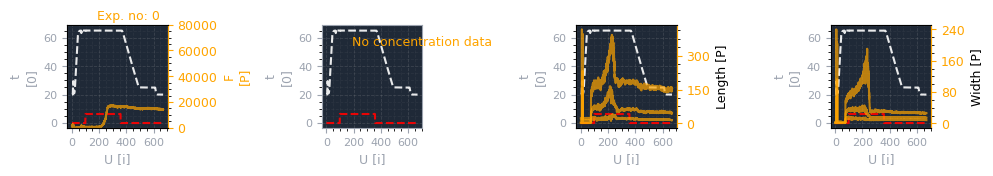

In [215]:
D = DataManager()
D.read_data_from =  r"C:\Users\abotondo\OneDrive - purdue.edu\ECNDATA\Desktop\ORCHESTRATOR_test"
D.data_reader()
D.COLUMNS
D.plot_generator()

print(column_names)

In [74]:
# NEXT CHAPTER

In [433]:
#from scipy.io import loadmat
#from scipy.io import savemat


#data = loadmat(r"C:\Users\user\12. OMNIBUS-IMED integration\2025_12_10_init_models.mat", squeeze_me=True, struct_as_record=True)
#savemat(r"C:\Users\user\modified.mat", data, do_compression=False)
#data

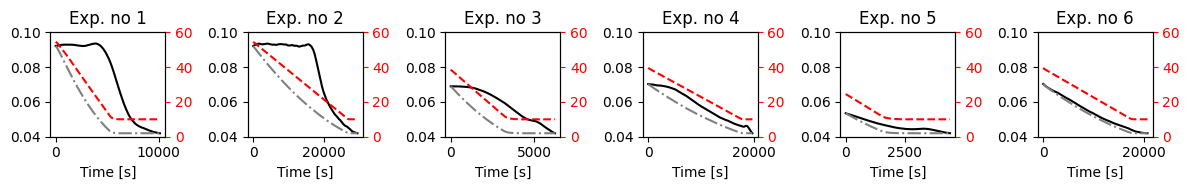

In [109]:
#fig, ax = plt.subplots(1,data['No'],figsize=(12,2) )
#for i in range(data['No']):
    
    #ax[i].plot(data['ExpData'][i][0][0],data['ExpData'][i][0][1],label='c',color='black')
    #ax[i].plot(data['ExpData'][i][4][0],solub(data['ExpData'][i][4][1]),'-.',label='sol',color='grey')
    #ax[i].set_xlabel("Time [s]")
    #ax[i].set_ylim([0.04,0.1])
    #ax[i].set_title(f'Exp. no {i+1:.0f}')
    #axT = ax[i].twinx()
    #axT.plot(data['ExpData'][i][4][0],data['ExpData'][i][4][1],'--',color='red',label='T')
    #axT.yaxis.label.set_color('red')
    #axT.tick_params(axis='y', colors='red')
    #axT.set_ylim([0,60])
    
#fig.tight_layout()